# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import GeoLifeCLEF2021Dataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Total number of patches: 19204


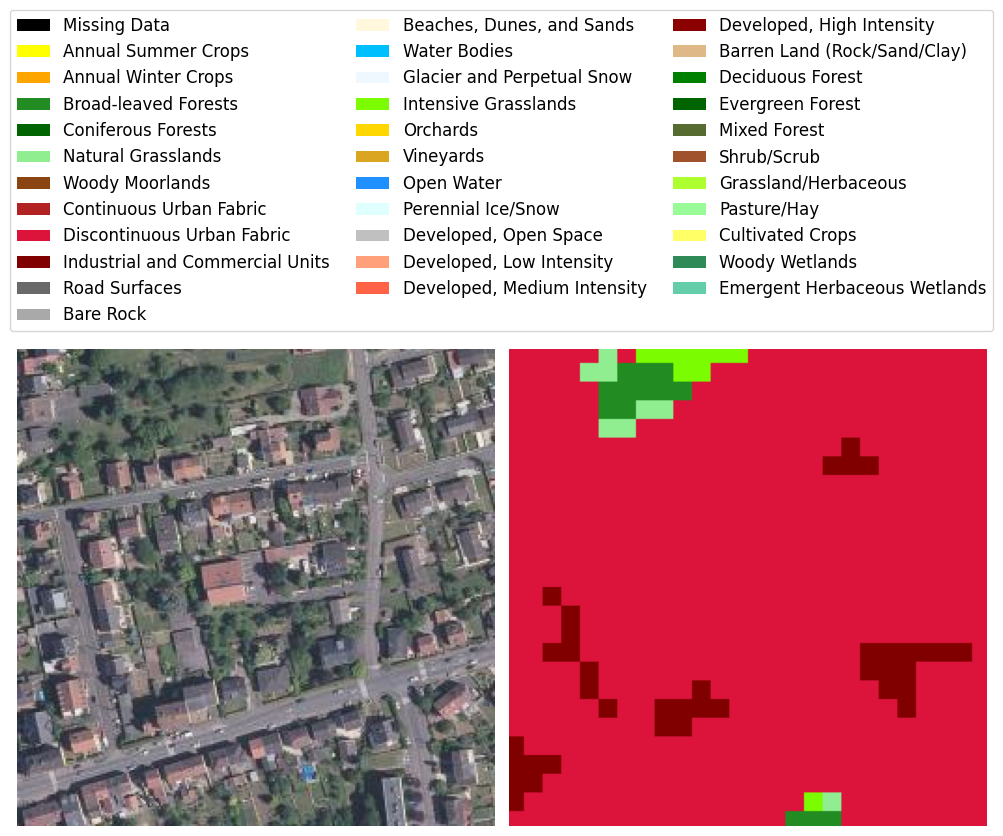

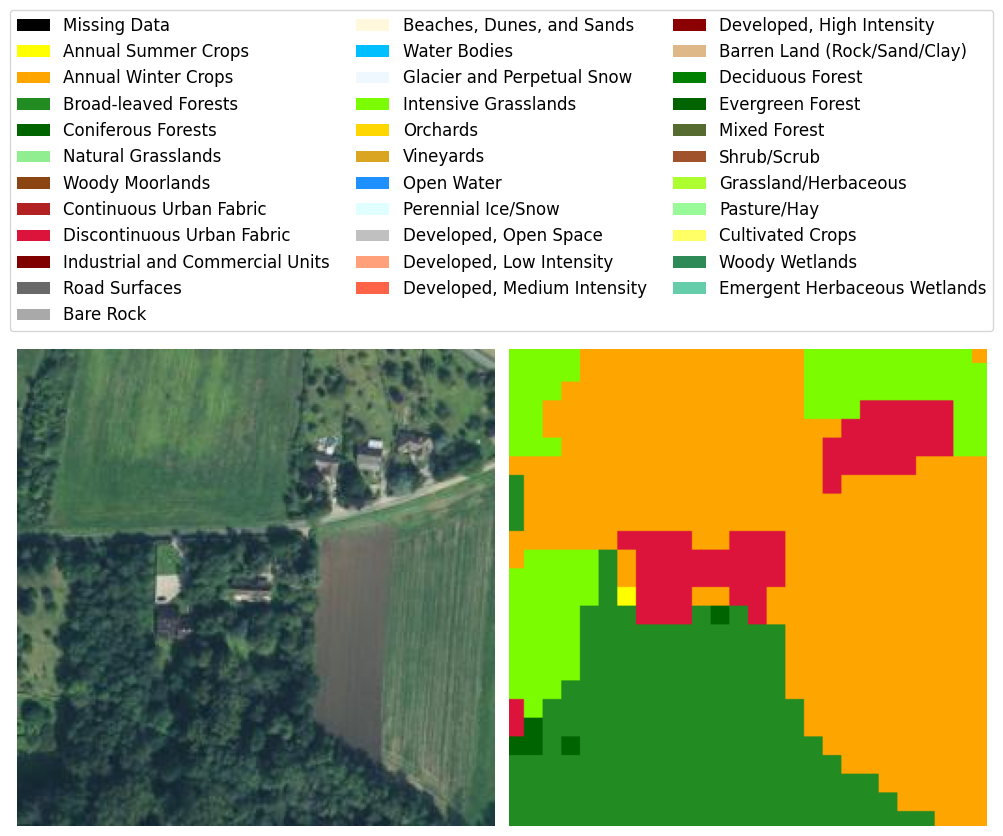

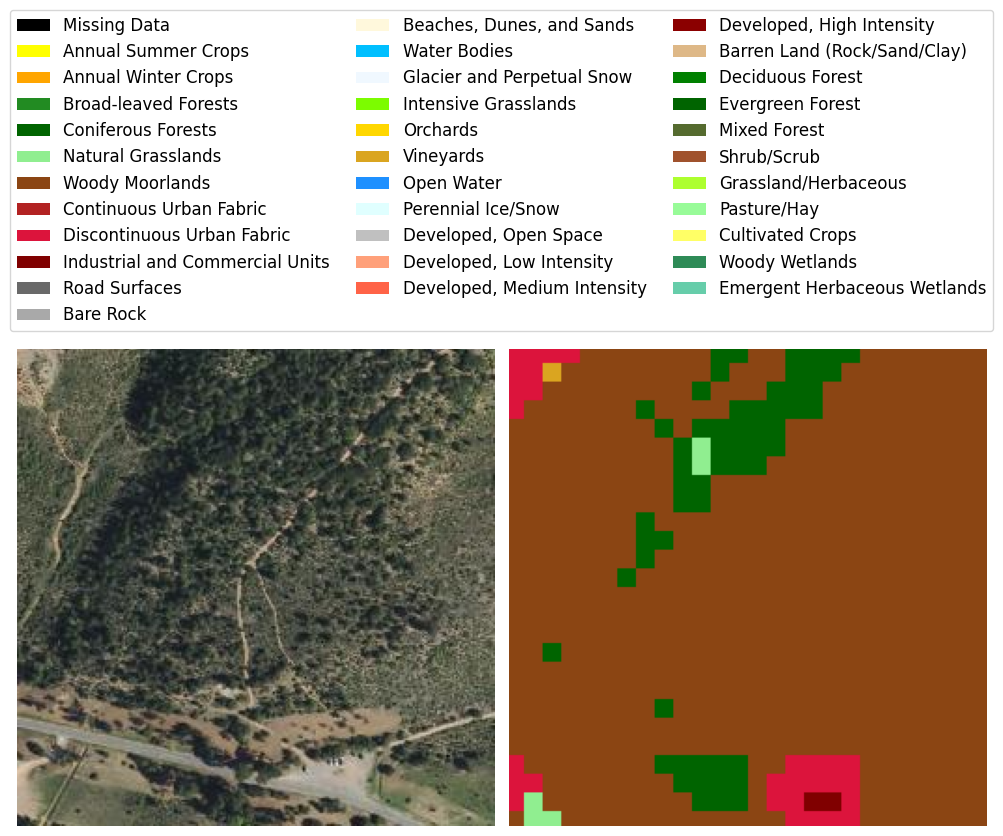

In [ ]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/geolifeclef2021/data/"
}
dataset = GeoLifeCLEF2021Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(3);
dataset.show_image(8);

In [38]:
dataset.data_distribution_table()

,Number of pixels
Missing Data,2320007.0
Annual Summer Crops,21546176.0
Annual Winter Crops,39032404.0
Broad-leaved Forests,54985000.0
Coniferous Forests,35699552.0
Natural Grasslands,47775724.0
Woody Moorlands,23536384.0
Continuous Urban Fabric,5954912.0
Discontinuous Urban Fabric,187393136.0
Industrial and Commercial Units,36286932.0


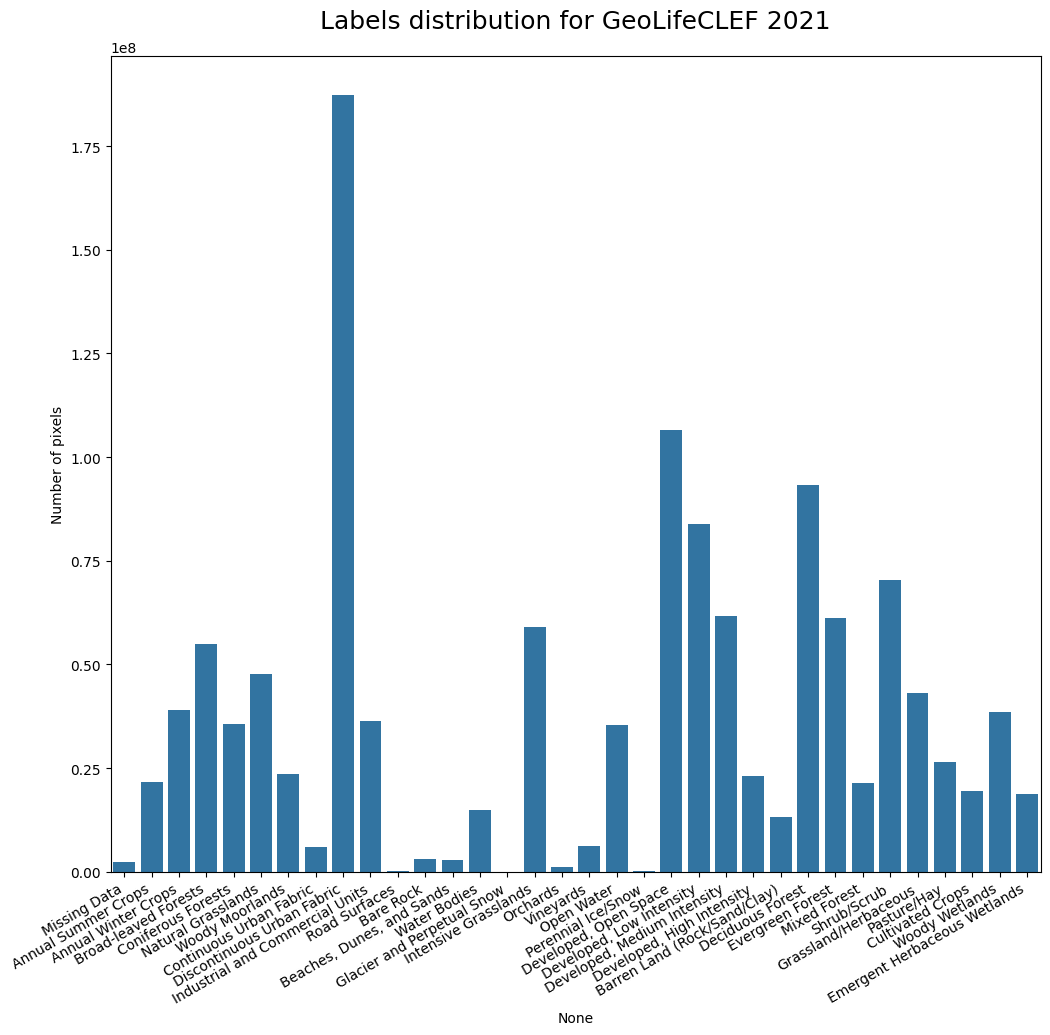

In [39]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/geolifeclef2021/data/",
    "mode": "train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = GeoLifeCLEF2021Dataset(train_dataset_config)
len(train_dataset)

18748

## Create the model

In [5]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/geolifeclef2021"
model_config = {
    "num_classes": 34, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-10-15 11:40:34,403 INFO Starting training.
training: 100%|██████████| 2344/2344 [04:18<00:00,  9.06it/s]
2025-10-15 11:44:53,129 INFO epoch: 1, time: 259, loss:  0.67266
testing on train set: 100%|██████████| 2344/2344 [02:26<00:00, 16.03it/s]
2025-10-15 11:47:20,817 INFO IOU:0.33552712043116506, IOU mean:0.1545324027007324, IOU per Class:[0.         0.         0.2598853  0.47743724 0.34973083 0.
 0.         0.         0.62197235 0.40827069 0.         0.
 0.         0.         0.         0.39975936 0.         0.
 0.4121207  0.         0.28570005 0.33192868 0.35549547 0.29889843
 0.         0.39562369 0.28752256 0.         0.36975634 0.
 0.         0.         0.         0.        ]
training: 100%|██████████| 2344/2344 [04:53<00:00,  7.98it/s]
2025-10-15 11:52:14,660 INFO epoch: 2, time: 294, loss:  0.53685
testing on train set: 100%|██████████| 2344/2344 [02:27<00:00, 15.85it/s]
2025-10-15 11:54:42,608 INFO IOU:0.34704543112429936, IOU mean:0.16369358998190855, IOU per Class:[0.   

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/geolifeclef2021/data/",
    "mode": "test",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = GeoLifeCLEF2021Dataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/geolifeclef2021/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

456


2025-10-15 13:24:03,722 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/geolifeclef2021/checkpoint.pth.tar
2025-10-15 13:24:04,120 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/geolifeclef2021/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 57/57 [00:04<00:00, 13.55it/s]


[{'IOU': 0.35653339441621196,
  'IOU mean': 0.16776432171591077,
  'IOU per Class': array([0.        , 0.        , 0.23804917, 0.50626006, 0.3930918 ,
         0.        , 0.        , 0.        , 0.68129094, 0.41227519,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.44330832, 0.        , 0.        , 0.34464696, 0.        ,
         0.29589134, 0.34568033, 0.35126676, 0.55708195, 0.        ,
         0.44148692, 0.40243812, 0.        , 0.29121908, 0.        ,
         0.        , 0.        , 0.        , 0.        ])}]

## Predictions

In [ ]:
import math
import matplotlib.pyplot as plt

def rearrange_figure_to_grid(fig, cols=8):
    '''
    The predictions will give 33 masks (one per class). 
    This function rearranges the figure to make it more readable.
    '''

    original_axes = fig.axes
    num_plots = len(original_axes)
    rows = math.ceil(num_plots / cols)

    # create a new figure
    new_fig, new_axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.5))
    new_axes = new_axes.flatten()

    for i, old_ax in enumerate(original_axes):
        # extract the image and title
        im = old_ax.images[0] if old_ax.images else None
        title = old_ax.get_title()

        # copy to new axis
        if im:
            new_axes[i].imshow(im.get_array(), cmap=im.get_cmap())
            new_axes[i].set_title(title, fontsize=13)
        new_axes[i].axis('off')

    # turn off any unused subplots
    for j in range(i + 1, len(new_axes)):
        new_axes[j].axis('off')

    plt.tight_layout()
    return new_fig

2025-10-15 13:41:58,121 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/geolifeclef2021/checkpoint.pth.tar
2025-10-15 13:41:58,529 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/geolifeclef2021/checkpoint.pth.tar at epoch 11


456


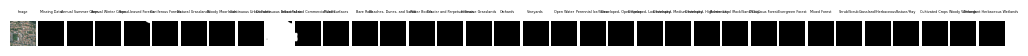

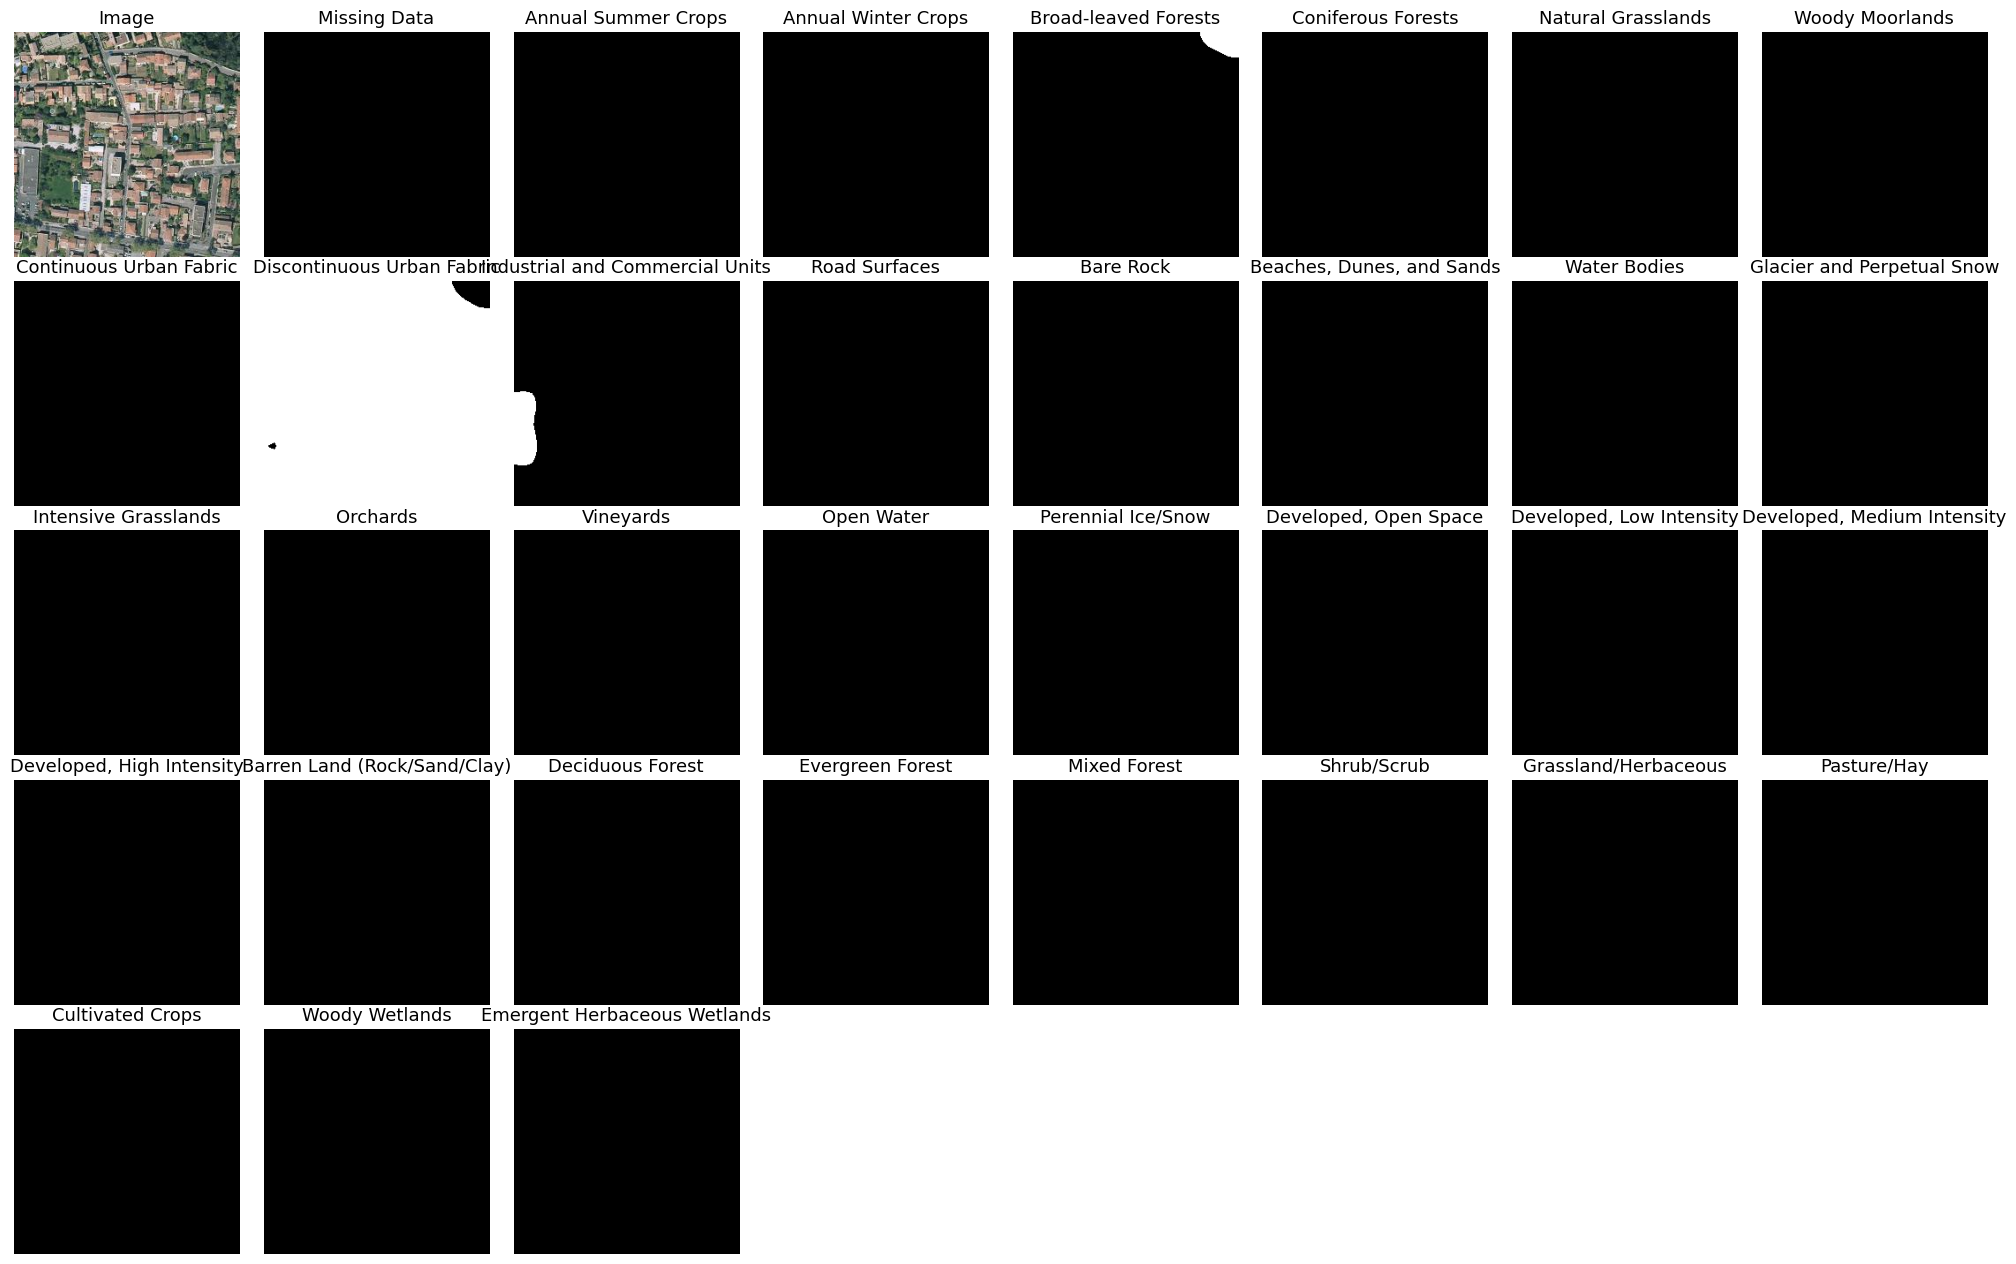

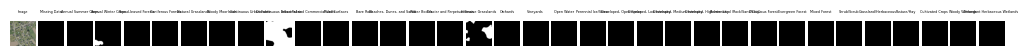

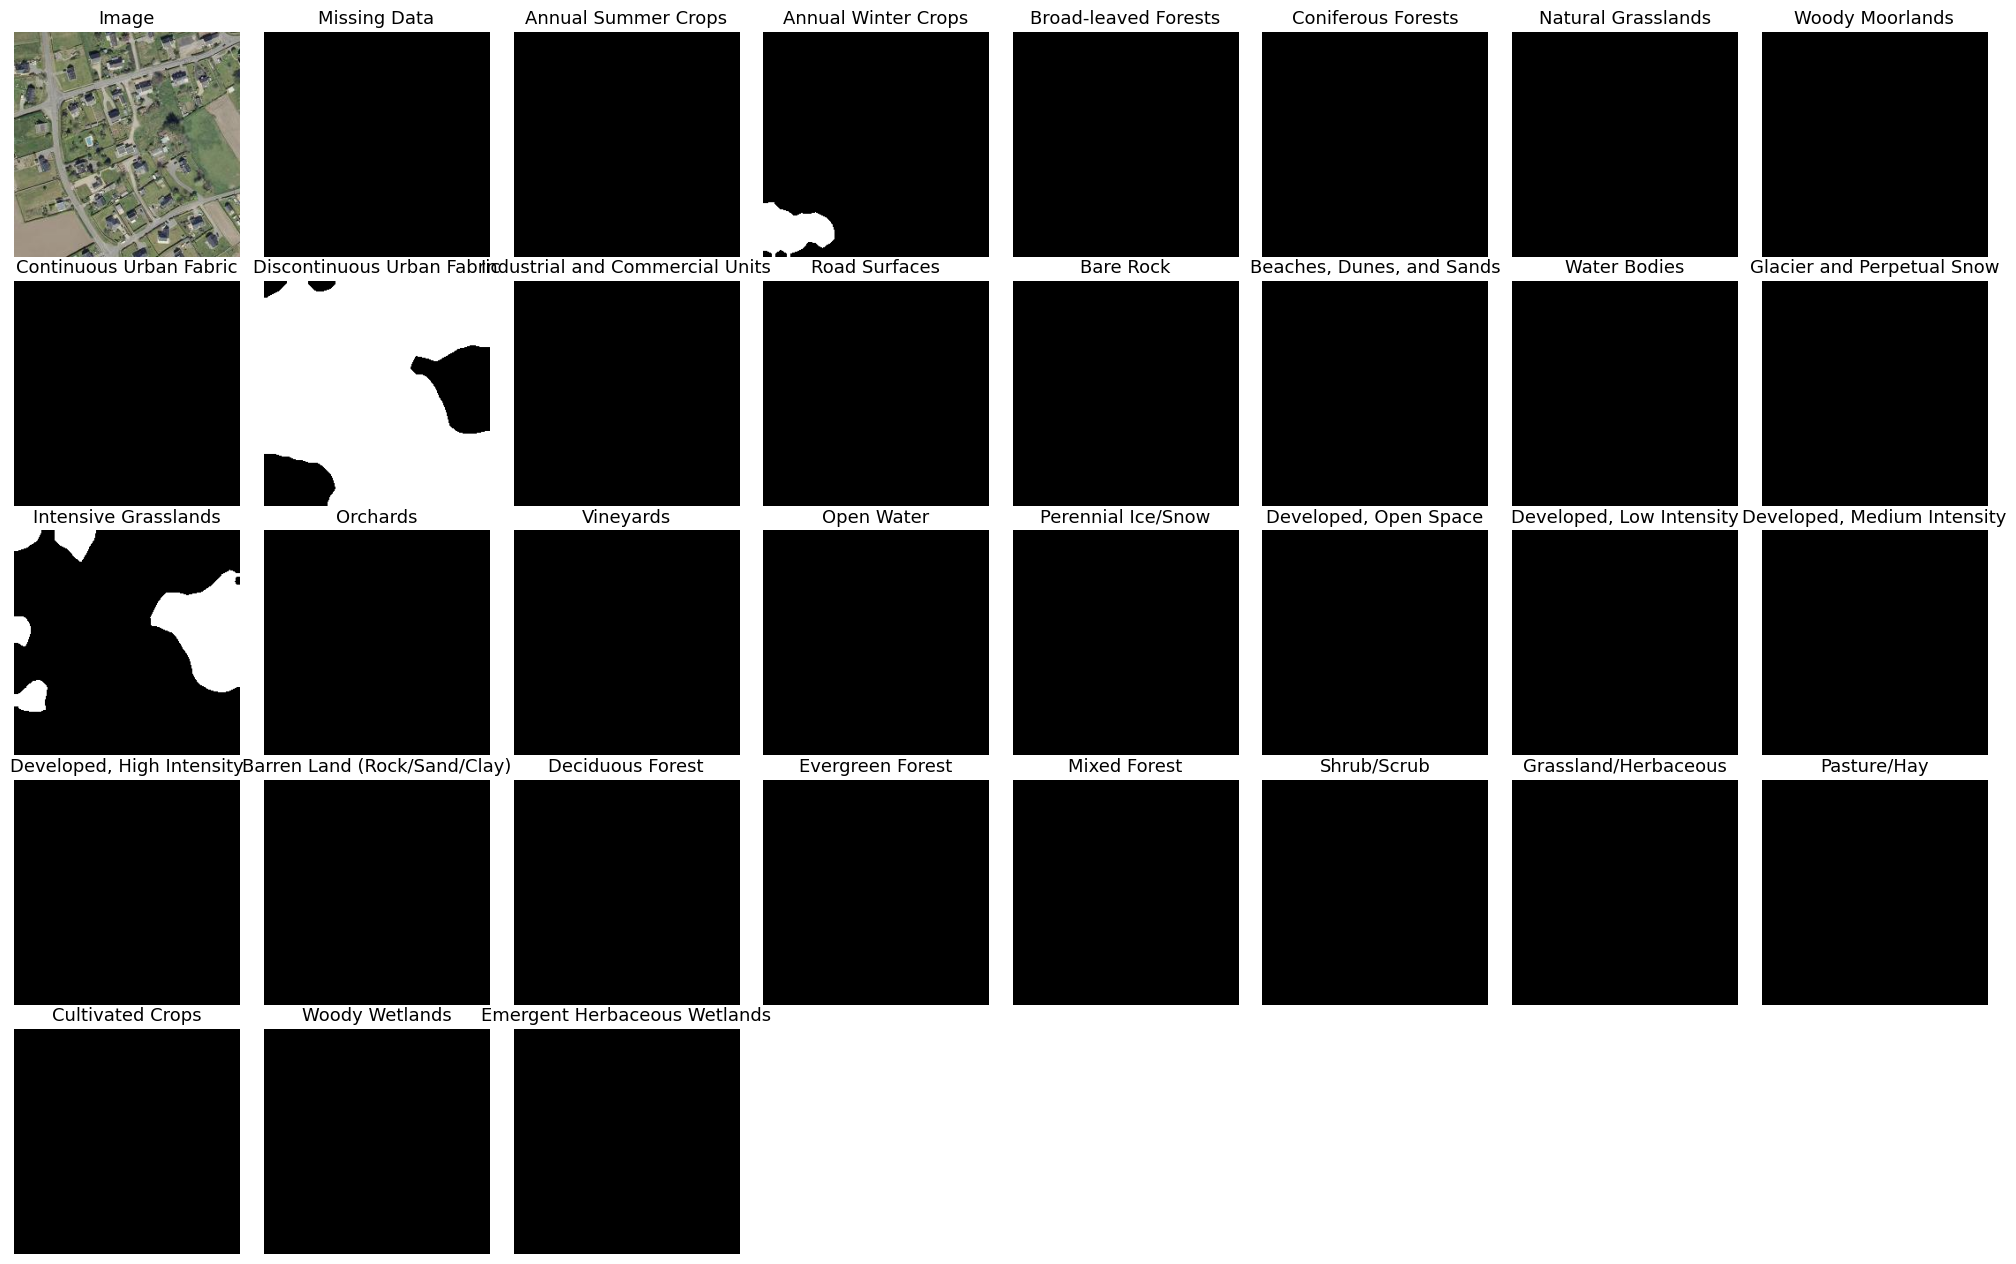

In [ ]:
model_path = "/home/dragik/data/FAIR_EO/experiments/geolifeclef2021/checkpoint.pth.tar"
labels = ["Missing Data",
    "Annual Summer Crops",
    "Annual Winter Crops",
    "Broad-leaved Forests",
    "Coniferous Forests",
    "Natural Grasslands",
    "Woody Moorlands",
    "Continuous Urban Fabric",
    "Discontinuous Urban Fabric",
    "Industrial and Commercial Units",
    "Road Surfaces",
    "Bare Rock",
    "Beaches, Dunes, and Sands",
    "Water Bodies",
    "Glacier and Perpetual Snow",
    "Intensive Grasslands",
    "Orchards",
    "Vineyards",
    "Open Water",
    "Perennial Ice/Snow",
    "Developed, Open Space",
    "Developed, Low Intensity",
    "Developed, Medium Intensity",
    "Developed, High Intensity",
    "Barren Land (Rock/Sand/Clay)",
    "Deciduous Forest",
    "Evergreen Forest",
    "Mixed Forest",
    "Shrub/Scrub",
    "Grassland/Herbaceous",
    "Pasture/Hay",
    "Cultivated Crops",
    "Woody Wetlands",
    "Emergent Herbaceous Wetlands"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
plt.rcParams.update({'font.size': 2})

test_dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/geolifeclef2021/data/",
    "mode": "test",
}

test_dataset = GeoLifeCLEF2021Dataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_masks(image, labels, transform)
new_fig = rearrange_figure_to_grid(fig, cols=8)
new_fig.show()

image = test_dataset[10][0]
fig = model.predict_masks(image, labels, transform)
new_fig = rearrange_figure_to_grid(fig, cols=8)
new_fig.show()